# Problem 1: exploring `data.p` and Tasks 1.1 / 1.2

`data.p` is **one moment in time** recorded by a KITTI-style car (see Fig. 1 of the PDF). It bundles:

| Group | Keys | What it is |
|---|---|---|
| Sensor data | `velodyne`, `image_2` | The LiDAR point cloud and the left color camera image, captured at the same instant |
| Calibration | `P_rect_X0`, `T_camX_velo`, `K_camX` | Matrices that tell you how the sensors are positioned and how a camera turns 3D into pixels |
| Per-point labels | `sem_label`, `labels`, `color_map` | A class ID for every LiDAR point, plus ID → name and ID → color lookups |
| Objects | `objects` | 3D bounding boxes of the cars in the scene |

The notebook walks through each element (printed values, then a picture where one makes sense), then solves Task 1.1 (project the points onto the image, colored by class) and Task 1.2 (also project the 3D boxes).

Switch `DATA_FILENAME` to `'demo.p'` to compare your output with the reference figure in the PDF.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch

from load_data import load_data

DATA_FILENAME = 'data.p'   # 'demo.p' matches Fig. 2 of the PDF
data = load_data(os.path.join('data', DATA_FILENAME))

np.set_printoptions(precision=4, suppress=True, linewidth=120)
plt.rcParams['figure.dpi'] = 110

print(f'{"key":<12} {"type":<10} details')
for k, v in data.items():
    if isinstance(v, np.ndarray):
        print(f'{k:<12} {"ndarray":<10} shape={v.shape}, dtype={v.dtype}')
    else:
        print(f'{k:<12} {type(v).__name__:<10} {len(v)} entries')

key          type       details
velodyne     ndarray    shape=(119454, 4), dtype=float32
image_2      ndarray    shape=(376, 1241, 3), dtype=int32
P_rect_00    ndarray    shape=(3, 4), dtype=float64
P_rect_10    ndarray    shape=(3, 4), dtype=float64
P_rect_20    ndarray    shape=(3, 4), dtype=float64
P_rect_30    ndarray    shape=(3, 4), dtype=float64
T_cam0_velo  ndarray    shape=(4, 4), dtype=float64
T_cam1_velo  ndarray    shape=(4, 4), dtype=float64
T_cam2_velo  ndarray    shape=(4, 4), dtype=float64
T_cam3_velo  ndarray    shape=(4, 4), dtype=float64
K_cam0       ndarray    shape=(3, 3), dtype=float64
K_cam1       ndarray    shape=(3, 3), dtype=float64
K_cam2       ndarray    shape=(3, 3), dtype=float64
K_cam3       ndarray    shape=(3, 3), dtype=float64
sem_label    ndarray    shape=(119454, 1), dtype=int32
color_map    dict       34 entries
labels       dict       34 entries
objects      list       7 entries


## 1. `velodyne`: the LiDAR point cloud

An array of shape `(num_points, 4)`. Each row is one laser return:

* columns 0–2: `x, y, z` in meters, in the **Velodyne frame**: x forward, y left, z up. The origin is the sensor itself, about 1.73 m above the road.
* column 3: reflectance, between 0 and 1 (how strongly the surface reflected the laser).

The scanner spins 360°, so the cloud surrounds the car, including everything behind it.

In [3]:
pts = data['velodyne']
print('shape:', pts.shape, '\n')
print('first 10 points (x, y, z, reflectance):')
print(pts[:10], '\n')

stats = pd.DataFrame(pts, columns=['x [m]', 'y [m]', 'z [m]', 'reflectance']).describe()
dist = np.linalg.norm(pts[:, :3], axis=1)
print(stats.round(3))
print(f'\ndistance from sensor: min {dist.min():.2f} m, median {np.median(dist):.2f} m, max {dist.max():.2f} m')

shape: (119454, 4) 

first 10 points (x, y, z, reflectance):
[[75.444   6.4594  2.7706  0.    ]
 [75.1615  6.6733  2.7617  0.    ]
 [75.4834  7.1802  2.7747  0.    ]
 [75.9658  7.4671  2.7918  0.    ]
 [67.0563  6.8013  2.4896  0.    ]
 [66.2767  6.9322  2.4636  0.    ]
 [66.0564  7.0142  2.4566  0.    ]
 [64.9369  7.1012  2.4196  0.    ]
 [64.9614  7.3111  2.4206  0.    ]
 [66.9488  7.748   2.4897  0.    ]] 

            x [m]       y [m]       z [m]  reflectance
count  119454.000  119454.000  119454.000   119454.000
mean       -0.652       1.524      -1.069        0.281
std        13.099       6.759       0.850        0.165
min       -80.512     -16.437     -11.364        0.000
25%        -5.101      -4.268      -1.784        0.190
50%        -0.059       0.373      -1.316        0.300
75%         4.060       6.286      -0.436        0.360
max        78.898      39.958       2.943        0.990

distance from sensor: min 1.29 m, median 7.63 m, max 80.52 m


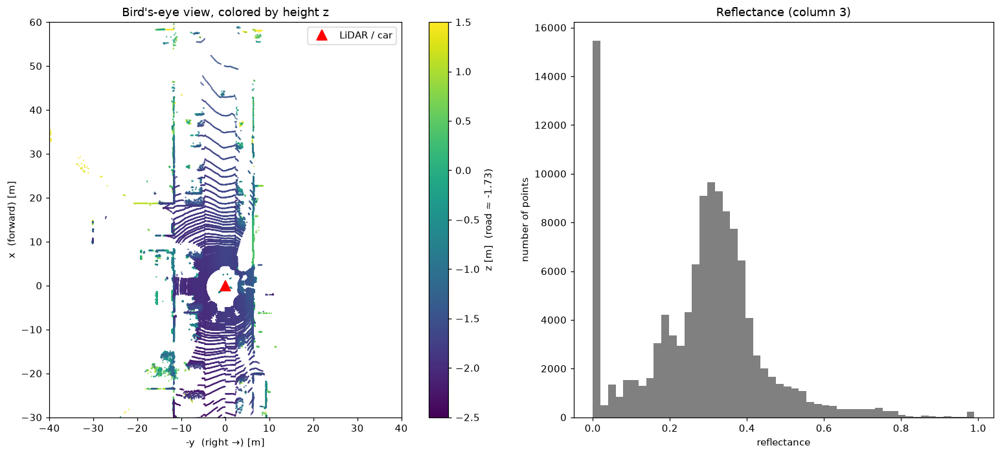

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={'width_ratios': [1.3, 1]})

# Bird's-eye view: look down from the sky. x (forward) points up the plot, y (left) points left.
ax = axes[0]
sc = ax.scatter(-pts[:, 1], pts[:, 0], c=pts[:, 2], s=0.2, cmap='viridis', vmin=-2.5, vmax=1.5) # "c" express the column we want to color by
ax.plot(0, 0, 'r^', ms=10, label='LiDAR / car')
ax.set_xlim(-40, 40); ax.set_ylim(-30, 60); ax.set_aspect('equal')
ax.set_xlabel('-y  (right →) [m]'); ax.set_ylabel('x  (forward) [m]')
ax.set_title("Bird's-eye view, colored by height z")
ax.legend(loc='upper right')
fig.colorbar(sc, ax=ax, label='z [m]  (road ≈ -1.73)')

# Reflectance distribution
ax = axes[1]
ax.hist(pts[:, 3], bins=50, color='gray')
ax.set_xlabel('reflectance'); ax.set_ylabel('number of points')
ax.set_title('Reflectance (column 3)')
plt.tight_layout(); plt.show()

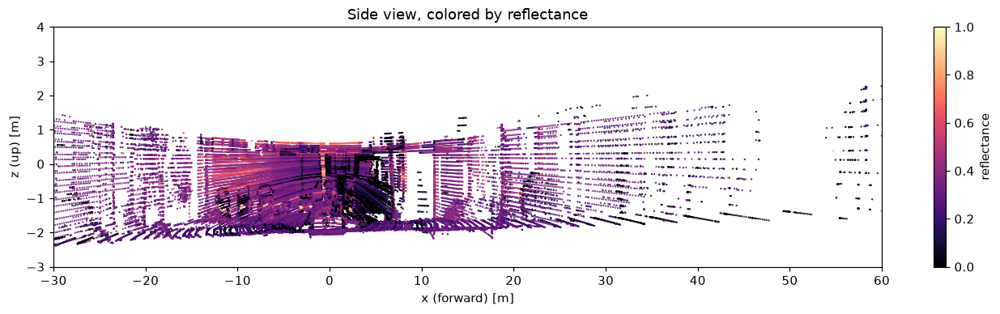

In [5]:
# Side view: shows the 64 laser rings fanning out from the sensor and the flat road at z ≈ -1.73 m
plt.figure(figsize=(15, 3.5))
plt.scatter(pts[:, 0], pts[:, 2], c=pts[:, 3], s=0.2, cmap='magma', vmax=1) # "c" express the column we want to color by
plt.xlim(-30, 60); plt.ylim(-3, 4)
plt.xlabel('x (forward) [m]'); plt.ylabel('z (up) [m]')
plt.title('Side view, colored by reflectance')
plt.colorbar(label='reflectance'); plt.show()

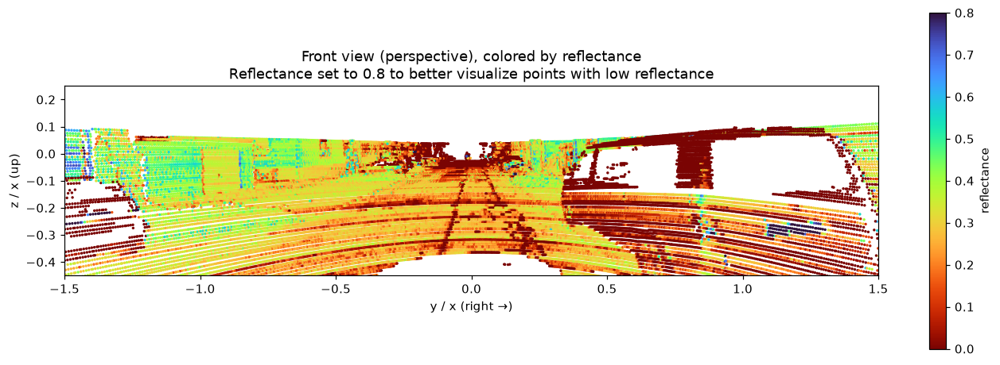

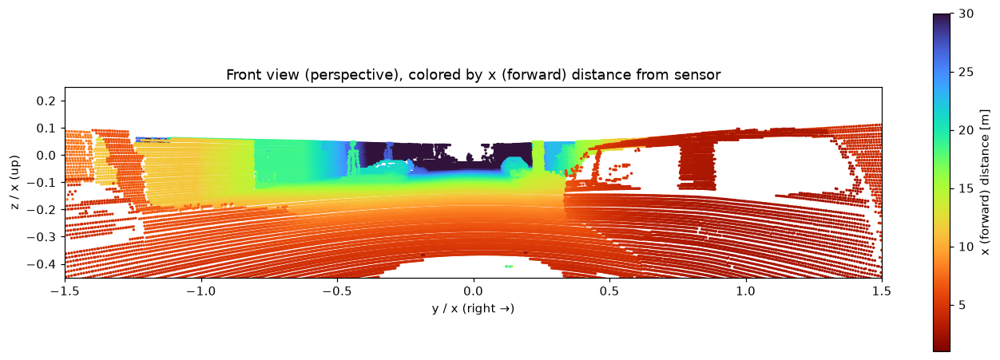

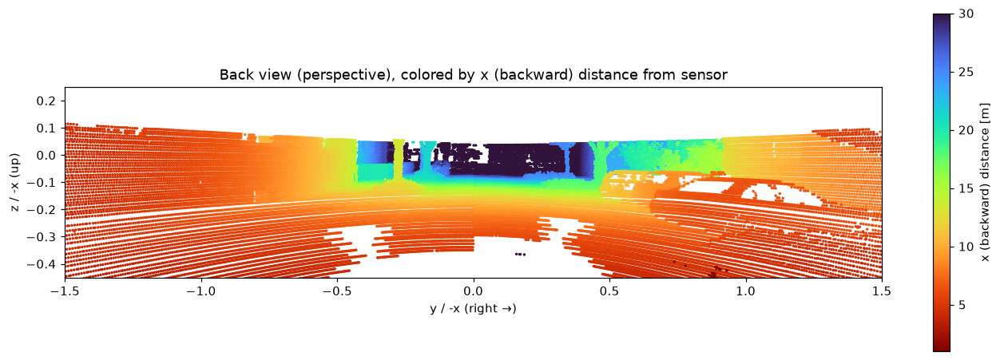

In [6]:
# Front view: shows the 64 laser rings fanning out from the sensor and the flat road at z ≈ -1.73 m
mask = pts[:, 0] > 1
p = pts[mask]
p = p[np.argsort(-p[:, 0])]  # sort by x (forward) distance from sensor

plt.figure(figsize=(15, 5))
plt.scatter(-p[:, 1] / p[:, 0], p[:, 2] / p[:, 0], c=p[:, 3], s=1.5, cmap='turbo_r', vmax=0.8) # "c" express the column we want to color by
plt.xlabel('y / x (right →)'); plt.ylabel('z / x (up)')
plt.xlim(-1.5, 1.5); plt.ylim(-0.45, 0.25); plt.gca().set_aspect('equal')
plt.title('Front view (perspective), colored by reflectance\nReflectance set to 0.8 to better visualize points with low reflectance')
plt.colorbar(label='reflectance')
plt.show()

plt.figure(figsize=(15, 5))
plt.scatter(-p[:, 1] / p[:, 0], p[:, 2] / p[:, 0], c=p[:, 0], s=1.5, cmap='turbo_r', vmax=30) # "c" express the column we want to color by
plt.xlabel('y / x (right →)'); plt.ylabel('z / x (up)')
plt.xlim(-1.5, 1.5); plt.ylim(-0.45, 0.25); plt.gca().set_aspect('equal')
plt.title('Front view (perspective), colored by x (forward) distance from sensor')
plt.colorbar(label='x (forward) distance [m]')
plt.show()


mask2 = pts[:, 0] < -1
p2 = pts[mask2]
p2 = p2[np.argsort(p2[:, 0])]  # sort by x (backward) distance from sensor
plt.figure(figsize=(15, 5))
plt.scatter(p2[:, 1] / -p2[:, 0], p2[:, 2] / -p2[:, 0], c=-p2[:, 0], s=1.5, cmap='turbo_r', vmax=30) # "c" express the column we want to color by
plt.xlabel('y / -x (right →)'); plt.ylabel('z / -x (up)')
plt.xlim(-1.5, 1.5); plt.ylim(-0.45, 0.25); plt.gca().set_aspect('equal')
plt.title('Back view (perspective), colored by x (backward) distance from sensor')
plt.colorbar(label='x (backward) distance [m]')
plt.show()

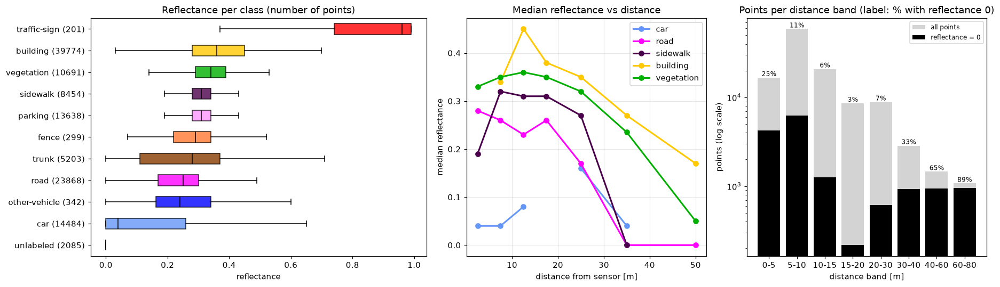

In [ ]:
# Reflectance by semantic class and by distance: material matters far more than range
sem_ids = data['sem_label'].ravel()
dist = np.linalg.norm(pts[:, :3], axis=1)
refl = pts[:, 3]
cls_rgb = lambda k: np.array(data['color_map'][k][::-1]) / 255   # color_map is BGR, so [::-1] reverses it to RGB and / 255 normalizes to [0, 1]

classes = [k for k in np.unique(sem_ids) if (sem_ids == k).sum() > 200] # only keep classes with more than 200 points
classes = sorted(classes, key=lambda k: np.median(refl[sem_ids == k])) # sort the classes by their median reflectance

fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={'width_ratios': [1.4, 1, 1]})

# 1. Distribution per class (box = middle 50% of the points, line = median)
ax = axes[0]
bp = ax.boxplot([refl[sem_ids == k] for k in classes], orientation='horizontal', showfliers=False, patch_artist=True)
for patch, k in zip(bp['boxes'], classes):
    patch.set_facecolor(cls_rgb(k)); patch.set_alpha(.8)
for med in bp['medians']:
    med.set_color('k')
ax.set_yticks(range(1, len(classes) + 1), [f'{data["labels"][k]} ({(sem_ids == k).sum()})' for k in classes])
ax.set_xlabel('reflectance'); ax.set_title('Reflectance per class (number of points)')

# 2. Median reflectance vs distance for the main classes
bins = np.array([0, 5, 10, 15, 20, 30, 40, 60, 80])
centers = (bins[:-1] + bins[1:]) / 2
ax = axes[1]
for name in ['car', 'road', 'sidewalk', 'building', 'vegetation']:
    k = [i for i, n in data['labels'].items() if n == name][0]
    med = [np.median(refl[(sem_ids == k) & (dist >= a) & (dist < b)])
           if ((sem_ids == k) & (dist >= a) & (dist < b)).sum() >= 20 else np.nan
           for a, b in zip(bins[:-1], bins[1:])]
    ax.plot(centers, med, 'o-', color=cls_rgb(k), label=name, lw=2)
ax.set_xlabel('distance from sensor [m]'); ax.set_ylabel('median reflectance')
ax.set_title('Median reflectance vs distance'); ax.legend(); ax.grid(alpha=.3)

# 3. Share of points per distance band, and how many of them read exactly 0
ax = axes[2]
counts = np.array([((dist >= a) & (dist < b)).sum() for a, b in zip(bins[:-1], bins[1:])])
zeros = np.array([((dist >= a) & (dist < b) & (refl == 0)).sum() for a, b in zip(bins[:-1], bins[1:])])
labels_bins = [f'{a}-{b}' for a, b in zip(bins[:-1], bins[1:])]
ax.bar(labels_bins, counts, color='lightgray', label='all points')
ax.bar(labels_bins, zeros, color='k', label='reflectance = 0')
for i, (n, z) in enumerate(zip(counts, zeros)):
    ax.text(i, n, f'{100 * z / n:.0f}%', ha='center', va='bottom', fontsize=8)
ax.set_yscale('log'); ax.set_xlabel('distance band [m]'); ax.set_ylabel('points (log scale)')
ax.set_title('Points per distance band (label: % with reflectance 0)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 2. `image_2`: the left color camera (Cam 2)

An array of shape `(height, width, 3)` with values from 0 to 255 (stored as `int32`, so it is cast to `uint8` before display). The PDF says the camera fires when the rotating LiDAR faces straight ahead, so the image and the point cloud show the same instant.

shape: (376, 1241, 3)  dtype: int32
top-left pixel (R, G, B): [66 53 58]


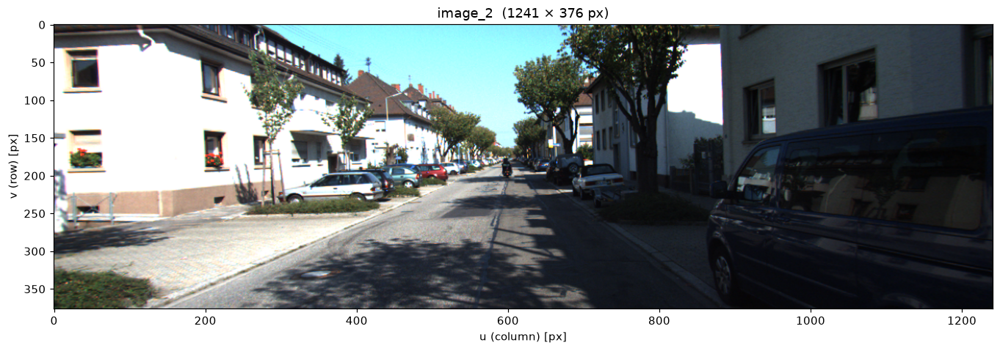

In [8]:
img = data['image_2'].astype(np.uint8)
H, W = img.shape[:2]
print('shape:', data['image_2'].shape, ' dtype:', data['image_2'].dtype)
print('top-left pixel (R, G, B):', data['image_2'][0, 0])

plt.figure(figsize=(15, 5))
plt.imshow(img)
plt.title(f'image_2  ({W} × {H} px)')
plt.xlabel('u (column) [px]'); plt.ylabel('v (row) [px]')
plt.show()

## 3. Calibration matrices

These say how to go from a 3D LiDAR point to a pixel. The car has four cameras (Fig. 1): Cam 0 and Cam 1 are grayscale, Cam 2 and Cam 3 are color. All four sit in a row, so they differ mainly by a sideways offset (the *baseline*). The naming is always `destination_origin`.

* **`T_camX_velo` (4×4)**: a rigid transform (rotation + translation) from Velodyne coordinates to **rectified camera X** coordinates. The camera frame uses x right, y down, z forward, so the rotation part mostly swaps axes.
* **`K_camX` (3×3)**: the intrinsics of camera X. `fx, fy` are the focal lengths in pixels and `cx, cy` is the principal point (roughly the image center).
* **`P_rect_X0` (3×4)**: projects a 3D point given in **rectified Cam 0** coordinates onto the image of camera X. Its left 3×3 block is K. Its last column contains the offset between Cam 0 and Cam X, so no separate transform is needed for that step.

In [9]:
for X in range(4):
    print(f'================ camera {X} ================')
    print(f'P_rect_{X}0 =\n{data[f"P_rect_{X}0"]}\n')
    print(f'K_cam{X} =\n{data[f"K_cam{X}"]}\n')
    print(f'T_cam{X}_velo =\n{data[f"T_cam{X}_velo"]}\n')

================ camera 0 ================
P_rect_00 =
[[718.856    0.     607.1928   0.    ]
 [  0.     718.856  185.2157   0.    ]
 [  0.       0.       1.       0.    ]]

K_cam0 =
[[718.856    0.     607.1928]
 [  0.     718.856  185.2157]
 [  0.       0.       1.    ]]

T_cam0_velo =
[[ 0.0004 -1.     -0.0081 -0.012 ]
 [-0.0072  0.0081 -0.9999 -0.054 ]
 [ 1.      0.0005 -0.0072 -0.2922]
 [ 0.      0.      0.      1.    ]]

================ camera 1 ================
P_rect_10 =
[[ 718.856     0.      607.1928 -386.1448]
 [   0.      718.856   185.2157    0.    ]
 [   0.        0.        1.        0.    ]]

K_cam1 =
[[718.856    0.     607.1928]
 [  0.     718.856  185.2157]
 [  0.       0.       1.    ]]

T_cam1_velo =
[[ 0.0004 -1.     -0.0081 -0.5492]
 [-0.0072  0.0081 -0.9999 -0.054 ]
 [ 1.      0.0005 -0.0072 -0.2922]
 [ 0.      0.      0.      1.    ]]

================ camera 2 ================
P_rect_20 =
[[718.856    0.     607.1928  45.3822]
 [  0.     718.856  185.2157  -0

In [10]:
# A few facts you can read off the matrices
K2, P2 = data['K_cam2'], data['P_rect_20']
print('fx, fy =', K2[0, 0], K2[1, 1], ' cx, cy =', K2[0, 2], K2[1, 2])
print('left 3x3 of P_rect_20 equals K_cam2:', np.allclose(P2[:, :3], K2))

print('\nSideways offset t_x = P[0,3] / fx of each camera relative to Cam 0 (positive = camera sits left of Cam 0):')
for X in range(4):
    P = data[f'P_rect_{X}0']
    print(f'  cam{X}: {P[0, 3] / P[0, 0]:+.4f} m')

print('\nThe same offset is the difference between T_cam2_velo and T_cam0_velo (translation x):')
print(f'  {data["T_cam2_velo"][0, 3] - data["T_cam0_velo"][0, 3]:+.4f} m')

R = data['T_cam0_velo'][:3, :3]
print('\nRotation part of T_cam0_velo (rounded): which Velodyne axis becomes which camera axis')
print(np.round(R).astype(int))
print('  cam x (right)   = -velo y (left)')
print('  cam y (down)    = -velo z (up)')
print('  cam z (forward) = +velo x (forward)')

fx, fy = 718.856 718.856  cx, cy = 607.1928 185.2157
left 3x3 of P_rect_20 equals K_cam2: True

Sideways offset t_x = P[0,3] / fx of each camera relative to Cam 0 (positive = camera sits left of Cam 0):
  cam0: +0.0000 m
  cam1: -0.5372 m
  cam2: +0.0631 m
  cam3: -0.4692 m

The same offset is the difference between T_cam2_velo and T_cam0_velo (translation x):
  +0.0631 m

Rotation part of T_cam0_velo (rounded): which Velodyne axis becomes which camera axis
[[ 0 -1  0]
 [ 0  0 -1]
 [ 1  0  0]]
  cam x (right)   = -velo y (left)
  cam y (down)    = -velo z (up)
  cam z (forward) = +velo x (forward)


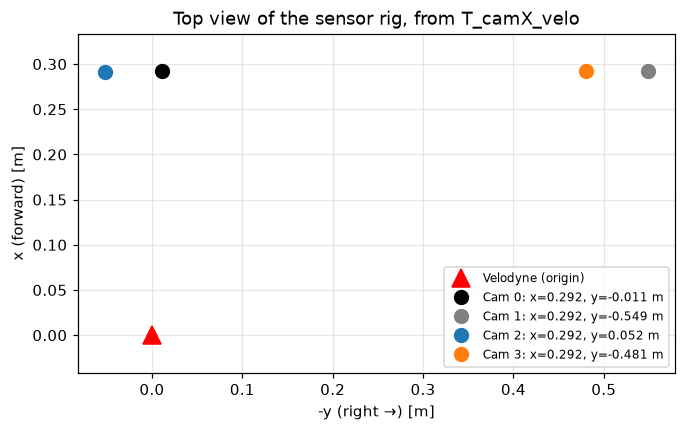

In [36]:
# Where are the cameras relative to the LiDAR? A camera center in the Velodyne frame is -R^T t.
plt.figure(figsize=(7, 4))
plt.plot(0, 0, 'r^', ms=12, label='Velodyne (origin)')
for X, col in zip(range(4), ['k', 'gray', 'tab:blue', 'tab:orange']):
    T = data[f'T_cam{X}_velo']
    c = -T[:3, :3].T @ T[:3, 3]
    plt.plot(-c[1], c[0], 'o', color=col, ms=9, label=f'Cam {X}: x={c[0]:.3f}, y={c[1]:.3f} m')
plt.xlabel('-y (right →) [m]'); plt.ylabel('x (forward) [m]')
plt.title('Top view of the sensor rig, from T_camX_velo')
plt.axis('equal'); plt.grid(alpha=.3); plt.legend(fontsize=8, loc='lower right'); plt.show()

**Projection recipe** (used in Task 1.1). For a LiDAR point `p = (x, y, z, 1)`:

1. `p_cam0 = T_cam0_velo @ p`: move it into rectified Cam 0 coordinates.
2. `(u', v', w) = P_rect_20 @ p_cam0`: project it with Cam 2's matrix.
3. Divide by depth: `u = u'/w`, `v = v'/w`.

Do **not** combine `T_cam2_velo` with `P_rect_20`. Both already contain the Cam 0 → Cam 2 offset, so it would be applied twice. `K_cam2 @ T_cam2_velo[:3]` is an equivalent alternative.

Object locations are given in Cam 0 coordinates, so the boxes only need step 2.

## 4. `labels` and `color_map`: dictionaries keyed by class ID

* `labels`: class ID → name (the SemanticKITTI classes).
* `color_map`: class ID → color as **BGR** (blue, green, red), not RGB. Matplotlib expects RGB, so reverse the list and divide by 255.

In [12]:
labels, color_map = data['labels'], data['color_map']
bgr2rgb = lambda c: np.array(c[::-1]) / 255.0

table = pd.DataFrame({
    'name': pd.Series(labels),
    'BGR (as stored)': pd.Series({k: v for k, v in color_map.items()}),
    'RGB (for matplotlib)': pd.Series({k: v[::-1] for k, v in color_map.items()}),
})
table.index.name = 'class ID'
table

,name,BGR (as stored),RGB (for matplotlib)
class ID,,,
0,unlabeled,"[0, 0, 0]","[0, 0, 0]"
1,outlier,"[0, 0, 255]","[255, 0, 0]"
10,car,"[245, 150, 100]","[100, 150, 245]"
11,bicycle,"[245, 230, 100]","[100, 230, 245]"
13,bus,"[250, 80, 100]","[100, 80, 250]"
15,motorcycle,"[150, 60, 30]","[30, 60, 150]"
16,on-rails,"[255, 0, 0]","[0, 0, 255]"
18,truck,"[180, 30, 80]","[80, 30, 180]"
20,other-vehicle,"[255, 0, 0]","[0, 0, 255]"


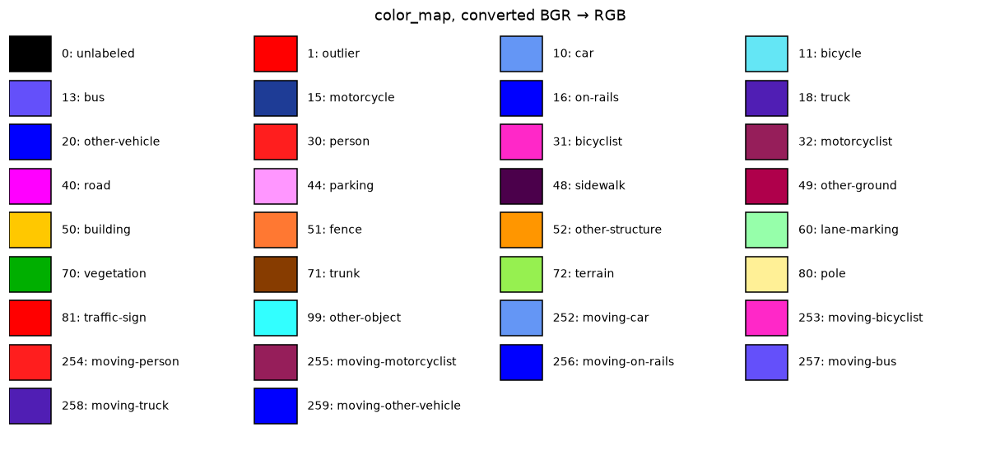

In [13]:
ids = sorted(color_map)
fig, ax = plt.subplots(figsize=(14, 6))
for i, k in enumerate(ids):
    r, c = divmod(i, 4)
    ax.add_patch(Rectangle((c * 3.5, -r), 0.6, 0.8, color=bgr2rgb(color_map[k]), ec='k'))
    ax.text(c * 3.5 + 0.75, -r + 0.4, f'{k}: {labels.get(k, "?")}', va='center', fontsize=9)
ax.set_xlim(0, 14); ax.set_ylim(-len(ids) / 4, 1); ax.axis('off')
ax.set_title('color_map, converted BGR → RGB'); plt.show()

## 5. `sem_label`: one class ID per LiDAR point

Row `i` of `sem_label` belongs to row `i` of `velodyne`. It is stored with shape `(num_points, 1)`, so `.ravel()` turns it into a flat array.

In [14]:
sem = data['sem_label'].ravel()
print('shape:', data['sem_label'].shape, '→', sem.shape)
print('first 20 labels:', sem[:20], '\n')

ids_present, counts = np.unique(sem, return_counts=True)
counts_df = pd.DataFrame({'name': [labels.get(i, '?') for i in ids_present],
                          'points': counts,
                          '%': (100 * counts / counts.sum()).round(2)},
                         index=pd.Index(ids_present, name='class ID'))
counts_df.sort_values('points', ascending=False)

shape: (119454, 1) → (119454,)
first 20 labels: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0] 



,name,points,%
class ID,,,
50,building,39774,33.30
40,road,23868,19.98
10,car,14484,12.13
44,parking,13638,11.42
70,vegetation,10691,8.95
48,sidewalk,8454,7.08
71,trunk,5203,4.36
0,unlabeled,2085,1.75
20,other-vehicle,342,0.29


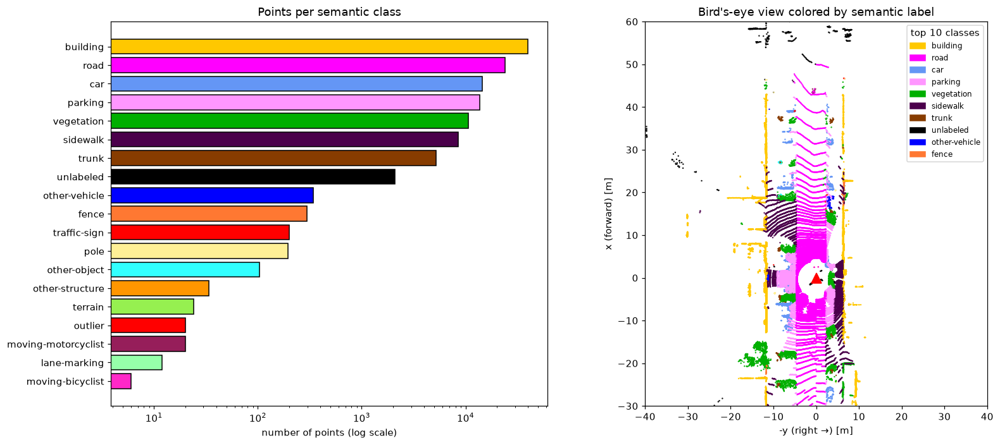

In [15]:
point_colors = np.array([bgr2rgb(color_map[i]) for i in sem])   # one RGB color per point

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={'width_ratios': [1, 1.3]})
order = np.argsort(counts)
axes[0].barh([labels[i] for i in ids_present[order]], counts[order],
             color=[bgr2rgb(color_map[i]) for i in ids_present[order]], edgecolor='k')
axes[0].set_xscale('log'); axes[0].set_xlabel('number of points (log scale)')
axes[0].set_title('Points per semantic class')

ax = axes[1]
ax.scatter(-pts[:, 1], pts[:, 0], c=point_colors, s=0.3)
ax.plot(0, 0, 'r^', ms=10)
ax.set_xlim(-40, 40); ax.set_ylim(-30, 60); ax.set_aspect('equal')
ax.set_xlabel('-y (right →) [m]'); ax.set_ylabel('x (forward) [m]')
ax.set_title("Bird's-eye view colored by semantic label")
ax.legend(handles=[Patch(color=bgr2rgb(color_map[i]), label=labels[i])
                   for i in ids_present[np.argsort(-counts)][:10]],
          fontsize=8, loc='upper right', title='top 10 classes')
plt.tight_layout(); plt.show()

## 6. `objects`: the annotated cars

A list with one entry per car. Each entry has 16 values (KITTI label format):

| Column(s) | Meaning |
|---|---|
| `type` | Always `'Car'` here |
| `truncated` | 0 = fully inside the image … 1 = leaves the image |
| `occluded` | 0 visible, 1 partly, 2 largely occluded, 3 unknown |
| `alpha` | Observation angle in [-π, π] |
| `left, top, right, bottom` | 2D box in the image, in pixels |
| `h, w, l` | 3D size: height, width, length (m) |
| `x, y, z` | 3D position in **Cam 0** coordinates (m): the center of the box's **bottom** face |
| `rotation_y` | Heading: rotation around Cam 0's y axis (vertical) |
| `score` | Detection confidence |

Task 1.2 only needs `h, w, l`, `x, y, z` and `rotation_y`.

In [16]:
OBJ_COLS = ['type', 'truncated', 'occluded', 'alpha', 'left', 'top', 'right', 'bottom',
            'h', 'w', 'l', 'x', 'y', 'z', 'rotation_y', 'score']
objects = pd.DataFrame(data['objects'], columns=OBJ_COLS)
print(f'{len(objects)} objects\n')
objects.round(3)

7 objects



,type,truncated,occluded,alpha,left,top,right,bottom,h,w,l,x,y,z,rotation_y,score
0,Car,0.0,0.0,-1.724,683.934,181.853,754.894,232.452,1.434,1.559,3.982,3.334,1.340,22.364,-1.578,0.831
1,Car,0.0,0.0,-2.818,294.434,194.537,437.220,242.381,1.348,1.562,3.715,-7.151,1.636,21.344,-3.138,0.787
2,Car,0.0,0.0,-2.166,844.299,38.839,1241.000,376.000,2.114,1.702,4.575,3.100,1.658,4.554,-1.597,0.683
3,Car,0.0,0.0,3.245,444.142,182.982,521.418,212.638,1.582,1.700,4.012,-6.815,1.464,39.334,3.074,0.659
4,Car,0.0,0.0,3.279,392.007,185.728,484.281,218.792,1.428,1.549,3.823,-7.529,1.452,32.014,3.050,0.659
5,Car,0.0,0.0,-1.678,658.533,168.575,704.161,211.586,1.850,1.644,3.974,3.273,1.136,32.919,-1.580,0.554
6,Car,0.0,0.0,-2.833,321.273,189.599,452.323,236.518,1.495,1.620,3.854,-7.316,1.647,23.896,-3.127,0.414


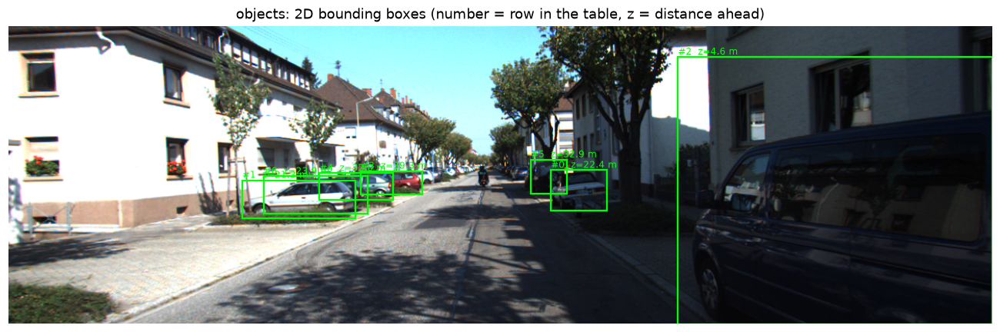

In [17]:
# The 2D boxes (columns left/top/right/bottom) drawn directly on the image
plt.figure(figsize=(15, 5))
plt.imshow(img)
for i, o in objects.iterrows():
    plt.gca().add_patch(Rectangle((o.left, o.top), o.right - o.left, o.bottom - o.top,
                                  fill=False, ec='lime', lw=1.5))
    plt.text(o.left, o.top - 3, f'#{i}  z={o.z:.1f} m', color='lime', fontsize=8)
plt.title('objects: 2D bounding boxes (number = row in the table, z = distance ahead)')
plt.axis('off'); plt.show()

## Task 1.1: project the point cloud onto the Cam 2 image

Steps:
1. Transform all points into rectified Cam 0 coordinates with `T_cam0_velo`.
2. **Filter**: keep points in front of the camera (depth z > 0). Points behind it would otherwise be projected upside-down into the image (hint in the PDF).
3. Project with `P_rect_20` and divide by depth.
4. Keep the points that land inside the image, and color them with `color_map` (BGR → RGB).

In [18]:
def velo_to_cam0(points_xyz, data):
    '''(N, 3) points in the Velodyne frame -> (N, 3) in the rectified Cam 0 frame.'''
    hom = np.hstack([points_xyz, np.ones((len(points_xyz), 1))])
    return (data['T_cam0_velo'] @ hom.T).T[:, :3]


def project_cam0_to_cam2(points_cam0, data):
    '''(N, 3) points in the rectified Cam 0 frame -> (N, 2) pixel coordinates (u, v) in image_2.'''
    hom = np.hstack([points_cam0, np.ones((len(points_cam0), 1))])
    uvw = (data['P_rect_20'] @ hom.T).T
    return uvw[:, :2] / uvw[:, 2:3]


def project_point_cloud(data, min_depth=0.1):
    '''Returns pixel coordinates, depth and semantic label of every LiDAR point visible in image_2.'''
    pts_cam0 = velo_to_cam0(data['velodyne'][:, :3], data)
    in_front = pts_cam0[:, 2] > min_depth
    uv = project_cam0_to_cam2(pts_cam0[in_front], data)

    H, W = data['image_2'].shape[:2]
    in_image = (uv[:, 0] >= 0) & (uv[:, 0] < W) & (uv[:, 1] >= 0) & (uv[:, 1] < H)
    sem = data['sem_label'].ravel()[in_front][in_image]
    return uv[in_image], pts_cam0[in_front][in_image, 2], sem


uv, depth, sem_vis = project_point_cloud(data)
print(f'{len(data["velodyne"])} points in total, {len(uv)} visible in Cam 2 '
      f'({100 * len(uv) / len(data["velodyne"]):.1f}%)')

119454 points in total, 17885 visible in Cam 2 (15.0%)


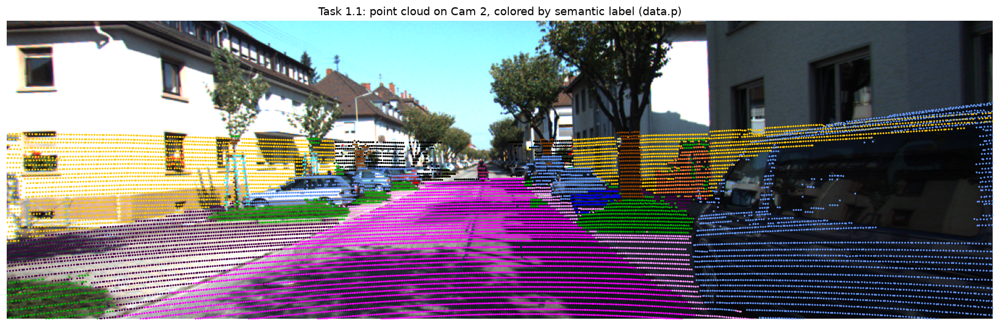

In [19]:
def show_projection(data, uv, sem_vis, ax=None, title=''):
    colors = np.array([bgr2rgb(data['color_map'][i]) for i in sem_vis])
    ax = ax or plt.gca()
    ax.imshow(data['image_2'].astype(np.uint8))
    ax.scatter(uv[:, 0], uv[:, 1], c=colors, s=4, marker='o', linewidths=0)
    ax.set_xlim(0, data['image_2'].shape[1]); ax.set_ylim(data['image_2'].shape[0], 0)
    ax.set_title(title); ax.axis('off')
    return ax


fig = plt.figure(figsize=(15, 5))
show_projection(data, uv, sem_vis, title=f'Task 1.1: point cloud on Cam 2, colored by semantic label ({DATA_FILENAME})')
plt.tight_layout()
fig.savefig(f'task1_1_{DATA_FILENAME[:-2]}.png', dpi=200, bbox_inches='tight')
plt.show()

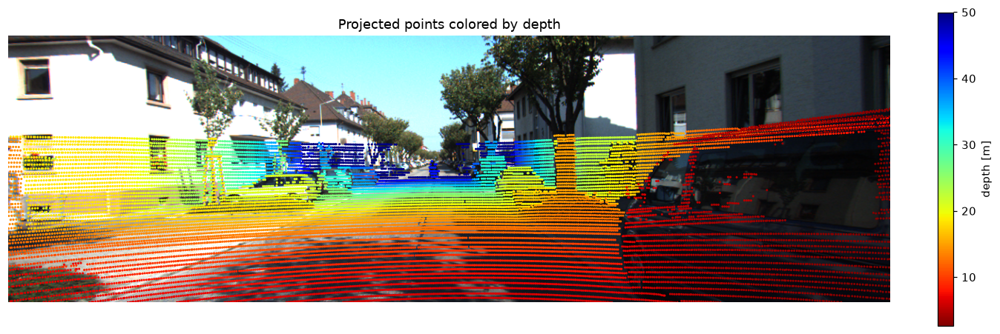

In [21]:
# The same projection colored by depth, which helps check that the geometry is right
plt.figure(figsize=(15, 5))
plt.imshow(img)
plt.scatter(uv[:, 0], uv[:, 1], c=depth, s=4, cmap='jet_r', marker='o', linewidths=0, vmax=50)
plt.colorbar(label='depth [m]', fraction=0.02)
plt.xlim(0, W); plt.ylim(H, 0); plt.axis('off'); plt.title('Projected points colored by depth'); plt.show()

## Task 1.2: add the 3D bounding boxes

Each box is described by its size `(h, w, l)`, the bottom-face center `(x, y, z)` in Cam 0 coordinates, and the heading `rotation_y`.

1. Build the 8 corners in the object's own frame. The camera's y axis points **down**, so the bottom face is at y = 0 and the top face at y = -h. Length runs along x and width along z:
```
        1 -------- 0          top face    (y = -h)
       /|         /|
      2 -------- 3 .
      | |        | |
      . 5 -------- 4          bottom face (y = 0)
      |/         |/
      6 -------- 7
```
2. Rotate around the vertical (y) axis by `rotation_y` and shift by `(x, y, z)`.
3. Project the 8 corners with `P_rect_20` (they are already in Cam 0 coordinates), then draw the 12 edges between them.

This corner order matches `self.connect` in `3dvis.py`, so the same function also works for Problem 1.3.

In [22]:
# 12 edges between the 8 corners (same pairs as self.connect in 3dvis.py)
BOX_EDGES = [(0, 1), (0, 3), (0, 4), (2, 1), (2, 3), (2, 6),
             (5, 1), (5, 4), (5, 6), (7, 3), (7, 4), (7, 6)]


def box_corners_cam0(obj):
    '''One row of data['objects'] -> (8, 3) box corners in the rectified Cam 0 frame.'''
    h, w, l = obj[8:11]
    x, y, z = obj[11:14]
    ry = obj[14]

    xs = np.array([ l,  l, -l, -l,  l,  l, -l, -l]) / 2
    ys = np.array([-h, -h, -h, -h,  0,  0,  0,  0])
    zs = np.array([-w,  w,  w, -w, -w,  w,  w, -w]) / 2

    R = np.array([[ np.cos(ry), 0, np.sin(ry)],
                  [ 0,          1, 0         ],
                  [-np.sin(ry), 0, np.cos(ry)]])
    return (R @ np.vstack([xs, ys, zs])).T + np.array([x, y, z])


all_corners = np.stack([box_corners_cam0(o) for o in data['objects']])   # (num_objects, 8, 3)
print('corners of object 0 (Cam 0 frame, meters):')
print(all_corners[0])

corners of object 0 (Cam 0 frame, meters):
[[ 4.0988 -0.0942 24.36  ]
 [ 2.5397 -0.0942 24.3486]
 [ 2.5688 -0.0942 20.367 ]
 [ 4.1279 -0.0942 20.3784]
 [ 4.0988  1.3397 24.36  ]
 [ 2.5397  1.3397 24.3486]
 [ 2.5688  1.3397 20.367 ]
 [ 4.1279  1.3397 20.3784]]


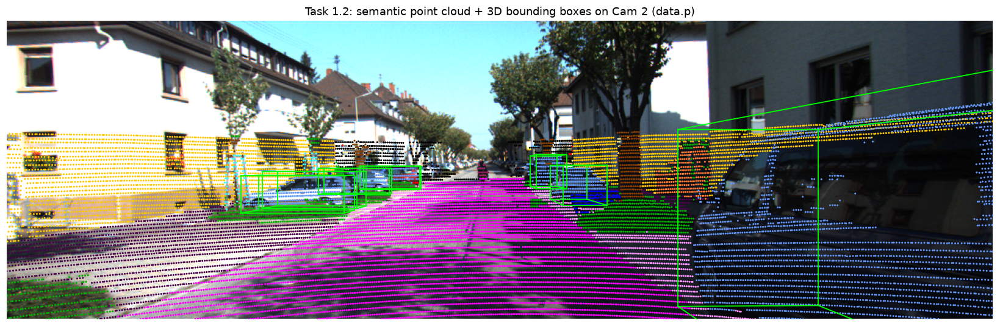

In [23]:
fig = plt.figure(figsize=(15, 5))
ax = show_projection(data, uv, sem_vis,
                     title=f'Task 1.2: semantic point cloud + 3D bounding boxes on Cam 2 ({DATA_FILENAME})')
for corners in all_corners:
    if np.any(corners[:, 2] <= 0.1):   # skip boxes that are (partly) behind the camera
        continue
    c2d = project_cam0_to_cam2(corners, data)
    for i, j in BOX_EDGES:
        ax.plot(c2d[[i, j], 0], c2d[[i, j], 1], color='lime', lw=1.2)
plt.tight_layout()
fig.savefig(f'task1_2_{DATA_FILENAME[:-2]}.png', dpi=200, bbox_inches='tight')
plt.show()

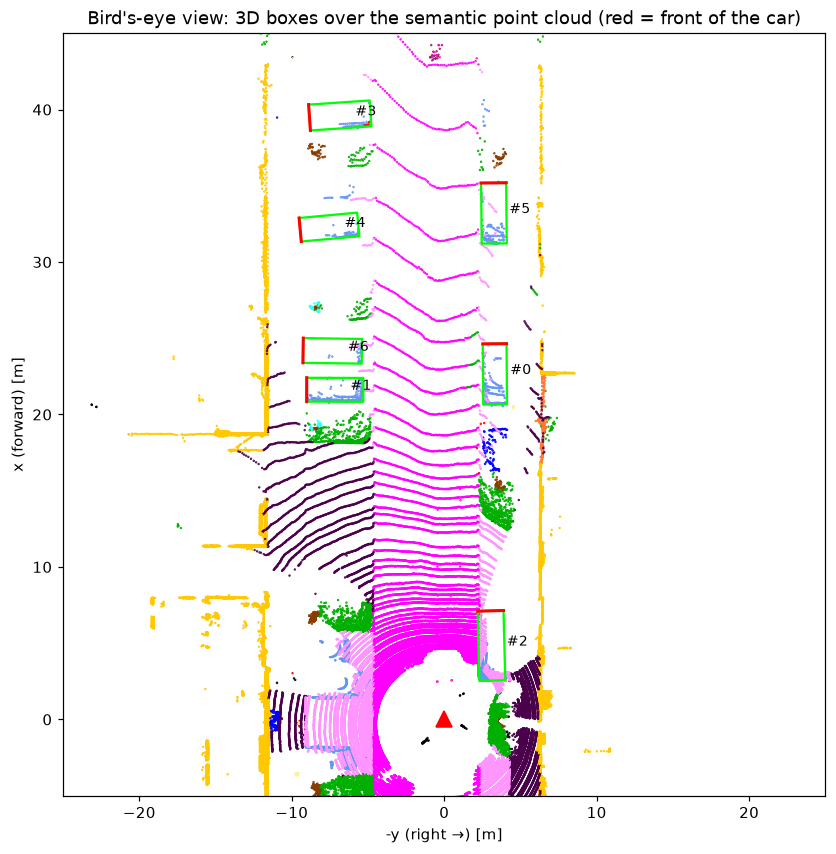

In [24]:
# Check: the same boxes seen from above, together with the LiDAR points (boxes moved into the Velodyne frame)
T_velo_cam0 = np.linalg.inv(data['T_cam0_velo'])
fig, ax = plt.subplots(figsize=(9, 9))
ax.scatter(-pts[:, 1], pts[:, 0], c=point_colors, s=0.3)
for k, corners in enumerate(all_corners):
    cv = (T_velo_cam0 @ np.hstack([corners, np.ones((8, 1))]).T).T
    bottom = cv[[4, 5, 6, 7, 4]]
    ax.plot(-bottom[:, 1], bottom[:, 0], color='lime', lw=1.5)
    ax.plot(-cv[[4, 5], 1], cv[[4, 5], 0], color='red', lw=2)   # front edge (heading)
    ax.text(-cv[:, 1].mean() + 1, cv[:, 0].mean(), f'#{k}', fontsize=9)
ax.plot(0, 0, 'r^', ms=10)
ax.set_xlim(-25, 25); ax.set_ylim(-5, 45); ax.set_aspect('equal')
ax.set_xlabel('-y (right →) [m]'); ax.set_ylabel('x (forward) [m]')
ax.set_title("Bird's-eye view: 3D boxes over the semantic point cloud (red = front of the car)")
plt.show()

## Task 1.3: the scene in 3D with `3dvis.py`

Projecting onto the image only shows what Cam 2 sees, and it is hard to judge a box from a 2D drawing. Here the scene is drawn in its native 3D space with the `Visualizer` from `3dvis.py`, modified to:

* color each point by its semantic label (`update(points, colors)`),
* draw all 3D boxes (`update_boxes(corners)`), with the corners moved from Cam 0 into the **Velodyne frame**, since that is the frame of the points,
* render to an image, so the views appear in the notebook and can be saved for the report.

The 3D view uses vispy with the PyQt6 backend. Set `INTERACTIVE = True` further down to open a window you can rotate (drag) and zoom (scroll).

In [25]:
import vispy
vispy.use('pyqt6')
from vispy.scene import visuals, SceneCanvas, cameras


class Visualizer():
    '''The Visualizer from 3dvis.py, modified for semantic colors and offscreen rendering.'''

    def __init__(self, show=False, size=(1600, 800)):
        self.canvas = SceneCanvas(keys='interactive', show=show, size=size, bgcolor='black')
        self.view = self.canvas.central_widget.add_view()
        self.view.camera = cameras.TurntableCamera(up='z', azimuth=90)

        # Point cloud visualizer
        self.sem_vis = visuals.Markers()
        self.view.add(self.sem_vis)
        visuals.XYZAxis(parent=self.view.scene)

        # Object detection visualizer (same corner order and edges as 3dvis.py / Task 1.2)
        self.obj_vis = visuals.Line()
        self.view.add(self.obj_vis)
        self.connect = np.asarray(BOX_EDGES)

    def update(self, points, colors):
        '''points: (N, 3) in the Velodyne frame, colors: (N, 3) RGB in [0, 1].'''
        self.sem_vis.set_data(points, face_color=colors, edge_width=0, size=3)

    def update_boxes(self, corners):
        '''corners: (num_boxes, 8, 3) in the Velodyne frame.'''
        connect = np.concatenate([self.connect + 8 * i for i in range(len(corners))])
        self.obj_vis.set_data(corners.reshape(-1, 3), connect=connect, width=2, color=[0, 1, 0, 1])

    def set_view(self, azimuth, elevation, distance, center):
        cam = self.view.camera
        cam.azimuth, cam.elevation, cam.distance, cam.center = azimuth, elevation, distance, center

    def render(self):
        return self.canvas.render()


def cam0_to_velo(points_cam0, data):
    '''(..., 3) points in the rectified Cam 0 frame -> the Velodyne frame.'''
    flat = points_cam0.reshape(-1, 3)
    hom = np.hstack([flat, np.ones((len(flat), 1))])
    return (np.linalg.inv(data['T_cam0_velo']) @ hom.T).T[:, :3].reshape(points_cam0.shape)


def show_render(image, title, filename=None):
    if filename:
        plt.imsave(filename, image)
    plt.figure(figsize=(16, 8))
    plt.imshow(image); plt.title(title); plt.axis('off'); plt.show()


corners_velo = cam0_to_velo(all_corners, data)   # (num_objects, 8, 3)
print('box corners in the Velodyne frame, object 0:')
print(corners_velo[0])

box corners in the Velodyne frame, object 0:
[[24.6536 -4.099  -0.1707]
 [24.6415 -2.5399 -0.1581]
 [20.6601 -2.5709 -0.1296]
 [20.6721 -4.13   -0.1423]
 [24.6433 -4.0874 -1.6046]
 [24.6312 -2.5283 -1.5919]
 [20.6497 -2.5594 -1.5634]
 [20.6618 -4.1185 -1.5761]]


### 1. Overview of the whole 360° scene

Every LiDAR point, colored by semantic label, with all the given boxes. The view looks forward from above and behind the car (compare with Fig. 3).

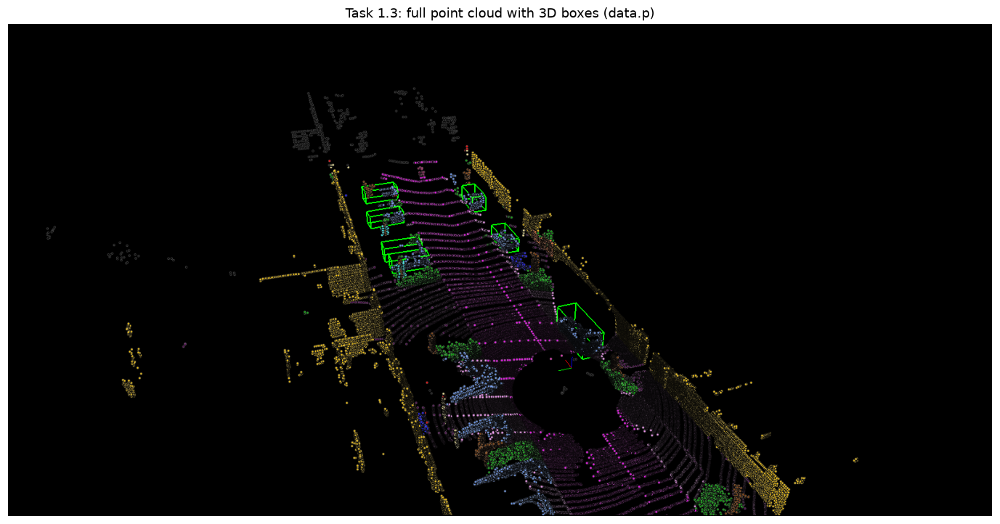

In [26]:
vis = Visualizer()
vis.update(pts[:, :3], point_colors)
vis.update_boxes(corners_velo)
vis.set_view(azimuth=-110, elevation=30, distance=55, center=(15, 0, 0))
show_render(vis.render(), f'Task 1.3: full point cloud with 3D boxes ({DATA_FILENAME})',
            f'task1_3_overview_{DATA_FILENAME[:-2]}.png')

### 2. Point cloud limited to the camera field of view

The boxes only cover cars that Cam 2 can see, so to count the missed cars, the cloud has to be reduced to the camera's field of view (hint in the PDF). A point is inside the FOV when it is in front of the camera **and** projects inside the image. That is the same test as in Task 1.1, but now it returns a mask over all points, so the 3D coordinates are kept.

17885 of 119454 points are in the camera FOV (15.0%)


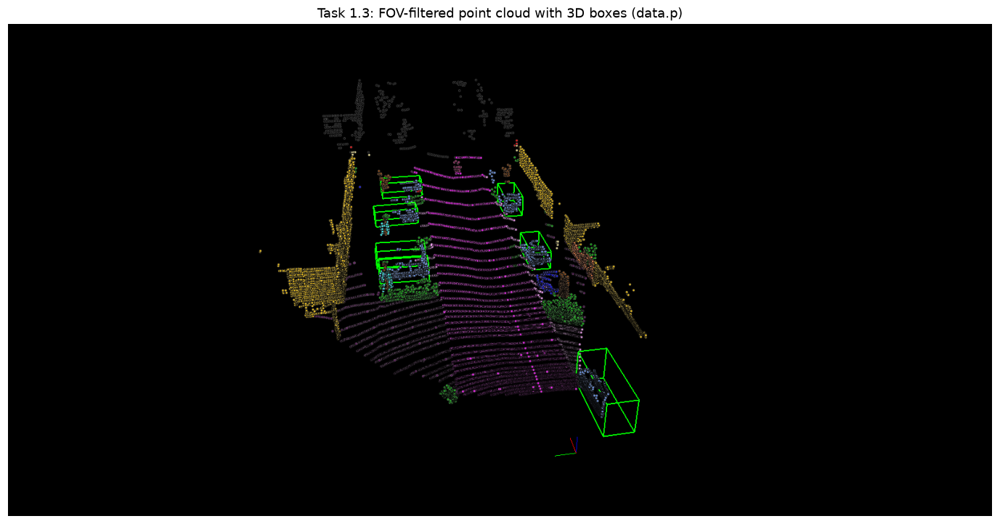

In [27]:
def fov_mask(data, min_depth=0.1):
    '''Boolean mask over all LiDAR points: True if the point is visible in image_2.'''
    pts_cam0 = velo_to_cam0(data['velodyne'][:, :3], data)
    mask = pts_cam0[:, 2] > min_depth
    uv = project_cam0_to_cam2(pts_cam0[mask], data)
    H, W = data['image_2'].shape[:2]
    mask[mask] = (uv[:, 0] >= 0) & (uv[:, 0] < W) & (uv[:, 1] >= 0) & (uv[:, 1] < H)
    return mask


fov = fov_mask(data)
print(f'{fov.sum()} of {len(fov)} points are in the camera FOV ({100 * fov.mean():.1f}%)')

vis_fov = Visualizer()
vis_fov.update(pts[fov, :3], point_colors[fov])
vis_fov.update_boxes(corners_velo)
vis_fov.set_view(azimuth=-100, elevation=28, distance=45, center=(20, 0, -1))
show_render(vis_fov.render(), f'Task 1.3: FOV-filtered point cloud with 3D boxes ({DATA_FILENAME})',
            f'task1_3_fov_{DATA_FILENAME[:-2]}.png')

In [ ]:
# open an interactive window (drag to rotate, scroll to zoom). The cell finishes when you close it.
INTERACTIVE = False  # set to True to open a window
SHOW_FOV_ONLY = False

if INTERACTIVE:
    win = Visualizer(show=True)
    sel = fov if SHOW_FOV_ONLY else np.ones(len(pts), bool)
    win.update(pts[sel, :3], point_colors[sel])
    win.update_boxes(corners_velo)
    win.set_view(azimuth=-100, elevation=28, distance=45, center=(20, 0, -1))
    vispy.app.run()

### 3. How many cars in the FOV did the network miss?

If the semantic labels are correct, every car in the FOV shows up as a group of `car` points (IDs 10 `car` and 252 `moving-car`). A car is missed when such a group has **no box around it**. To check this beyond eyeballing:

1. Test every FOV car point against every box, in the box's own frame: undo the location and rotation, then compare with half of `l`, `w` and the height range. A 20 cm margin allows for points right on the car's surface.
2. Group the leftover car points into clusters (points closer than 0.7 m are connected).
3. Look at each cluster in the image and from above.

In [29]:
from scipy.spatial import cKDTree
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

CAR_IDS = [10, 252]   # car, moving-car


def points_in_boxes(points_cam0, objects, margin=0.2):
    '''Boolean mask: True if a point (rectified Cam 0 frame) lies inside any of the 3D boxes.'''
    inside = np.zeros(len(points_cam0), bool)
    for obj in objects:
        h, w, l = obj[8:11]
        loc, ry = np.array(obj[11:14]), obj[14]
        R = np.array([[ np.cos(ry), 0, np.sin(ry)],
                      [ 0,          1, 0         ],
                      [-np.sin(ry), 0, np.cos(ry)]])
        q = (points_cam0 - loc) @ R          # = R^T (p - loc): point in the box's own frame
        inside |= ((np.abs(q[:, 0]) <= l / 2 + margin) & (np.abs(q[:, 2]) <= w / 2 + margin)
                   & (q[:, 1] <= margin) & (q[:, 1] >= -h - margin))   # y points down: bottom at 0, top at -h
    return inside


def cluster(points, radius=0.7):
    '''Connected components of points closer than radius. Returns one label per point.'''
    pairs = cKDTree(points).query_pairs(radius, output_type='ndarray')
    n = len(points)
    graph = coo_matrix((np.ones(len(pairs)), (pairs[:, 0], pairs[:, 1])), shape=(n, n))
    return connected_components(graph, directed=False)[1]


sem = data['sem_label'].ravel()
is_car = np.isin(sem, CAR_IDS)
in_box = points_in_boxes(velo_to_cam0(pts[:, :3], data), data['objects'])

print(f'car points in the whole scene : {is_car.sum()}')
print(f'car points in the FOV         : {(is_car & fov).sum()}')
print(f'  ... inside a box            : {(is_car & fov & in_box).sum()}')
print(f'  ... NOT inside any box      : {(is_car & fov & ~in_box).sum()}')
print(f'car points outside the FOV not inside any box: {(is_car & ~fov & ~in_box).sum()}  '
      '(why the full 360° cloud would give a wrong count)')

missed_idx = np.where(is_car & fov & ~in_box)[0]
rows = []
if len(missed_idx):
    clusters = cluster(pts[missed_idx, :3])
    for c in np.unique(clusters):
        q = pts[missed_idx[clusters == c], :3]
        rows.append({'points': len(q), 'x (forward) [m]': q[:, 0].mean(), 'y (left) [m]': q[:, 1].mean(),
                     'height above road [m]': q[:, 2].mean() + 1.73, 'distance [m]': np.linalg.norm(q[:, :2].mean(0))})
    missed_clusters = clusters
missed = pd.DataFrame(rows).sort_values('points', ascending=False).round(2) if rows else pd.DataFrame()
print(f'\n{len(missed)} group(s) of car points without a box:')
missed

car points in the whole scene : 14484
car points in the FOV         : 3147
  ... inside a box            : 3120
  ... NOT inside any box      : 27
car points outside the FOV not inside any box: 6659  (why the full 360° cloud would give a wrong count)

2 group(s) of car points without a box:


,points,x (forward) [m],y (left) [m],height above road [m],distance [m]
1,18,34.340000,6.78,1.36,35.000000
0,9,39.720001,-2.66,1.37,39.810001


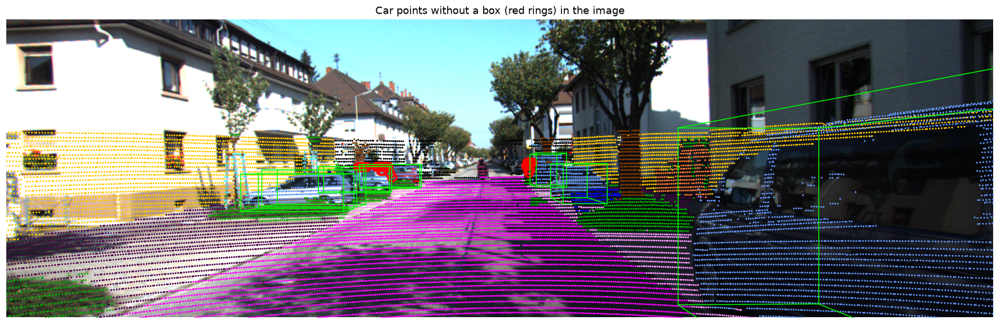

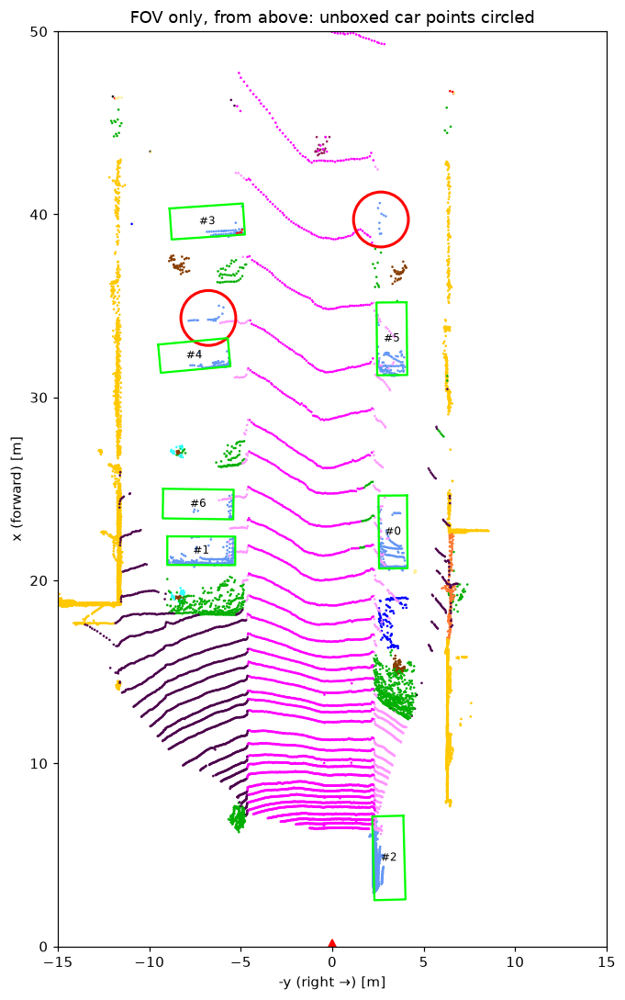

In [30]:
# Where are those groups? First in the image, then from above (FOV points only).
fig, ax = plt.subplots(figsize=(16, 5.5))
show_projection(data, uv, sem_vis, ax=ax, title='Car points without a box (red rings) in the image')
if len(missed_idx):
    uv_missed = project_cam0_to_cam2(velo_to_cam0(pts[missed_idx, :3], data), data)
    ax.scatter(*uv_missed.T, s=90, facecolors='none', edgecolors='red', lw=2)
for corners in all_corners:
    if np.all(corners[:, 2] > 0.1):
        c2d = project_cam0_to_cam2(corners, data)
        for i, j in BOX_EDGES:
            ax.plot(c2d[[i, j], 0], c2d[[i, j], 1], color='lime', lw=1)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 10))
ax.scatter(-pts[fov, 1], pts[fov, 0], c=point_colors[fov], s=0.5)
for k, cv in enumerate(corners_velo):
    b = cv[[4, 5, 6, 7, 4]]
    ax.plot(-b[:, 1], b[:, 0], color='lime', lw=1.5)
    ax.text(-cv[:, 1].mean(), cv[:, 0].mean(), f'#{k}', fontsize=8, ha='center', va='center')
if len(missed_idx):
    for c in np.unique(missed_clusters):
        q = pts[missed_idx[missed_clusters == c]]
        ax.add_patch(plt.Circle((-q[:, 1].mean(), q[:, 0].mean()), 1.5, fill=False, ec='red', lw=2))
ax.plot(0, 0, 'r^', ms=10)
ax.set_xlim(-15, 15); ax.set_ylim(0, 50); ax.set_aspect('equal')
ax.set_xlabel('-y (right →) [m]'); ax.set_ylabel('x (forward) [m]')
ax.set_title("FOV only, from above: unboxed car points circled")
plt.tight_layout(); plt.show()

**Answer for `data.p`:** **2 cars** in the camera FOV have no bounding box.

* **Left side, about 35 m ahead** (x ≈ 34.3 m, y ≈ 6.8 m): about 18 car points in the 5.4 m gap between boxes #4 and #3. The cars on that side are parked perpendicular to the road, about 2 m wide along x, so another car fits there. It is mostly hidden behind box #4, so the LiDAR only hits its top.
* **Right side, about 40 m ahead** (x ≈ 39.7 m, y ≈ -2.7 m): about 9 car points about 5 m beyond box #5. In the image it is the dark car just behind the boxed SUV.

Both are far away and heavily occluded, so they have very few points, which is exactly where a detector is most likely to fail.

Things that do **not** count:
* The blue cluster at about 19 m on the right is labeled `other-vehicle`, not `car`.
* The cars further down the street in the image have no `car`-labeled LiDAR points, so with the labels taken as correct they are not counted.
* Without the FOV filter, about 6,700 unboxed car points behind and beside the car (outside the camera's view) would wrongly add many more "missed" cars.

Run the cells above and look at the overview and FOV renders (or the interactive window) to confirm this for the report. With `demo.p`, only 1 car point in the FOV has no box, so nothing is missed there.